In [94]:
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque


# Environment

maze = np.array([
    [0,0,1,0,0,0,1,0,0,0],
    [1,0,1,0,1,0,1,0,1,0],
    [1,0,0,0,1,0,0,0,1,0],
    [1,1,1,0,1,1,1,0,1,0],
    [0,0,0,0,0,0,1,0,0,0],
    [0,1,1,1,1,0,1,1,1,0],
    [0,0,0,0,1,0,0,0,1,0],
    [1,1,1,0,1,1,1,0,1,0],
    [0,0,0,0,0,0,0,0,1,0],
    [0,1,1,1,1,1,1,0,0,0]
])

pop_size=100
chro_len=40
max_generation=200
start = (0, 0)
goal = (9, 9)

# BFS 

def bfs(maze, start, goal):
    queue = deque([(start, [])])
    visited = set()
    
    while queue:
        current, path = queue.popleft()
        x, y = current
        
        if current == goal:
            return path + [current]
        
        if current in visited:
            continue
        
        visited.add(current)
        
        for dx, dy in [(0, 1), (0, -1), (1, 0), (-1, 0)]:

            nx, ny = x + dx, y + dy

            if 0 <= nx < len(maze) and 0 <= ny < len(maze[0]) and maze[nx][ny] != 1:

                queue.append(((nx, ny), path + [current]))
    
    return " Failed:NO path found"

# Population

def initial_population(pop_size,chro_len):
    population=[]
    for p in range(pop_size):
        Chromosome=[]
        for c in range(chro_len):
            r=random.randint(0,3)
            Chromosome.append(r)
        population.append(Chromosome)
    return population


# Fitness Function

def fitness_function(maze,population,start,goal):
    fitness_score=[]
    moves={
        0:(-1,0),
        1:(0,1),
        2:(1,0),
        3:(0,-1)
    }
    for f in range(pop_size):
        x, y = start
        invalid_moves = 0
        for gene in population[f]:
            dx,dy=moves[gene]
            x_new=x+dx
            y_new=y+dy
            if (0<=x_new<len(maze) and 0<=y_new<len(maze[0]) and maze[x_new][y_new]==0):
                x,y=x_new,y_new
            else:
                invalid_moves=invalid_moves+1
            if (x,y)==goal:
                break
        distance=abs(goal[0]-x)+abs(goal[1]-y)
        fitness=(100/(1+distance))-(2*invalid_moves)
        if(x,y)==goal:
            fitness=fitness+1000
        fitness_score.append(fitness)
    return fitness_score

# selection


def tournment_selection(population,fitness_score,k=3):
    selected_parents = []
    pop_size=len(population)

    for round_num in range(pop_size):
 
      best_index = random.randint(0, pop_size - 1)
 
      for player in range(k - 1):
        competitor = random.randint(0, pop_size - 1)
        if fitness_score[competitor] > fitness_score[best_index]:
          best_index = competitor
      selected_parents.append(population[best_index])
    return selected_parents


# crossover

def crossover(selected_parent,chro_len):
    offsprings=[]
    for i in range(0, len(selected_parent), 2):
        crossoverPoint = random.randint(1, chro_len-1)
        offspring1= selected_parent[i][0:crossoverPoint]+selected_parent[i+1][crossoverPoint:]

        # Mutation is applied here so offspring are returned fully updated
        # after crossover without needing a separate mutation call later

        offspring1=mutation(offspring1,mutation_rate=.05) 
        offspring2= selected_parent[i+1][0:crossoverPoint]+selected_parent[i][crossoverPoint:]
        offspring2=mutation(offspring2,mutation_rate=.05)
        offsprings.append(offspring1)
        offsprings.append(offspring2)

    return offsprings

# mutation

def mutation(chromosome,mutation_rate):

    for i in range(len(chromosome)):
       if random.random()< mutation_rate:
           r=random.randint(0,3)
           while(chromosome[i] ==r):
                r=random.randint(0,3)
           chromosome[i]=r
    return chromosome

# GA_Run

def run_genetic_algorithm(pop_size,chro_len,max_generation):
    population=initial_population(pop_size,chro_len)
    print(f"Initial population: {population}")

    best_fitness=[]
    for gen in range(max_generation):
        fitness_scores=fitness_function(maze,population,start,goal)
        current_best=max(fitness_scores)
        best_fitness.append(current_best)

        if current_best >= 1000:
            reason_of_stop = f"Goal reached at generation {gen}"
            print(reason_of_stop)
            break


        if len(best_fitness)>5 and len(set(best_fitness[-5:]))==1:
            reason_of_stop=f"convergence reached at generation {gen}"
            print(reason_of_stop)
            break

        selected_parent=tournment_selection(population,fitness_scores,k=3)
        next_generation=[]
        offsprings=crossover(selected_parent,chro_len)
        next_generation.extend(offsprings)
        
        population=next_generation[:pop_size]
        print(f"Gen {gen+1} , best fitness: {current_best} , population: {population}")

        if(gen==max_generation-1):
            reason_of_stop=f"Reached maximum generations"
            print(reason_of_stop)

    final_fitness=fitness_function(maze,population,start,goal)
    best_val=population[final_fitness.index(max(final_fitness))]
    print(f"algorithm complete")

    return best_val,reason_of_stop



# Visualization

def visualize_maze(maze, start,goal, path, algorithm):

    cmap = ListedColormap(['white', 'black'])

    fig, ax = plt.subplots()

    ax.imshow(maze, cmap=cmap)

    if algorithm=='BFS':
        for node in path[1:-1]:
            ax.scatter(node[1], node[0],
                       color='blue',
                       marker='o',
                       )
        ax.scatter([], [], color='blue', marker='o', label='BFS Path')
        ax.set_title("BFS Algorithm")

    if algorithm=='GA':
        for node in path[1:-1]:
            
            ax.scatter(node[1], node[0],
                       color='red',
                       marker='s',
                       )
        ax.scatter([], [], color='red', marker='s', label='GA Path')
        ax.set_title("Genetic Algorithm")

    ax.scatter(start[1], start[0],
               color='gold',
               marker='x',
               label='Start')

    ax.scatter(goal[1], goal[0],
               color='lime',
               marker='*',
               label='Goal',
               s=120)


    ax.legend()
    plt.show()


# decode chromosome

def decode_chromosome(chromosome, maze, start):
    x, y = start
    path = [(x, y)]
    
    moves = {
        0: (-1, 0),
        1: (0, 1),
        2: (1, 0),
        3: (0, -1)
    }

    for gene in chromosome:
       
        if (x,y)==goal:
            break
        
        dx, dy = moves[gene]
        x_new, y_new = x + dx, y + dy
        
        if (0 <= x_new < len(maze) and 
            0 <= y_new < len(maze[0]) and 
            maze[x_new][y_new] == 0):
            
            x, y = x_new, y_new
            path.append((x, y))

    return path



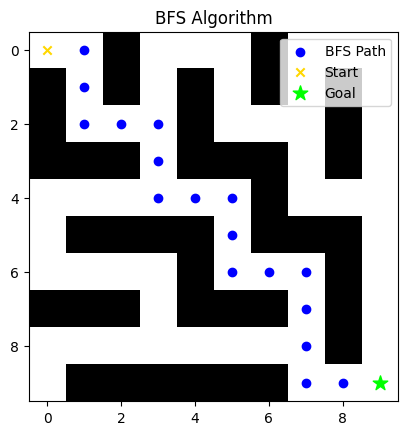

Initial population: [[1, 3, 1, 3, 3, 3, 3, 1, 2, 3, 3, 0, 1, 0, 1, 2, 1, 1, 1, 1, 3, 0, 0, 0, 0, 2, 2, 1, 3, 3, 1, 1, 1, 3, 2, 1, 1, 3, 3, 2], [1, 2, 0, 0, 0, 2, 1, 1, 2, 2, 1, 3, 2, 0, 3, 1, 1, 0, 2, 3, 0, 2, 3, 3, 1, 0, 1, 0, 2, 1, 1, 1, 1, 1, 0, 1, 2, 3, 0, 2], [0, 3, 0, 2, 0, 1, 3, 3, 1, 2, 2, 1, 2, 3, 0, 2, 1, 0, 0, 2, 1, 0, 1, 2, 0, 1, 1, 3, 0, 1, 2, 2, 1, 3, 2, 2, 1, 2, 1, 0], [1, 1, 1, 0, 1, 2, 3, 0, 0, 2, 0, 0, 3, 3, 1, 2, 0, 0, 2, 1, 1, 1, 0, 1, 3, 1, 0, 2, 2, 0, 0, 3, 0, 3, 0, 1, 0, 1, 3, 3], [1, 0, 0, 0, 0, 2, 2, 0, 2, 1, 3, 3, 0, 3, 0, 2, 3, 2, 0, 3, 0, 0, 2, 0, 3, 1, 0, 2, 3, 2, 1, 1, 1, 1, 2, 2, 1, 0, 3, 3], [2, 1, 3, 2, 1, 1, 3, 3, 0, 2, 0, 2, 0, 3, 0, 1, 2, 3, 2, 2, 0, 0, 2, 0, 0, 2, 3, 2, 0, 3, 1, 2, 2, 0, 0, 2, 0, 0, 2, 0], [3, 0, 1, 1, 3, 0, 0, 2, 0, 1, 0, 3, 0, 3, 1, 3, 0, 0, 1, 2, 2, 0, 0, 3, 1, 3, 0, 1, 2, 2, 1, 1, 1, 2, 1, 3, 3, 1, 1, 1], [1, 1, 2, 0, 3, 3, 2, 0, 0, 3, 3, 0, 1, 3, 2, 3, 2, 2, 3, 2, 3, 2, 2, 3, 1, 2, 3, 3, 1, 0, 2, 0, 1, 0, 3, 1, 3, 1, 2, 0], [2,

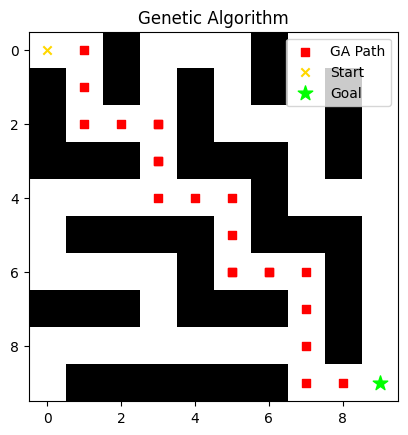

In [95]:
# Run

path=bfs(maze, start, goal)
visualize_maze(maze, start, goal, path,'BFS')
chromosome,reason_of_stop=run_genetic_algorithm(pop_size,chro_len,max_generation)
path2=decode_chromosome(chromosome, maze, start)
visualize_maze(maze, start, goal, path2,'GA')
     
